# Sentinel‑2 / Hunga Tonga Analysis  

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from rasterio.plot import show
import os


In [12]:
# extracting google earth images
earth_dir = Path("sentinel-data/White_light")
images = sorted(list(earth_dir.glob("*.jpg")))

image = plt.imread(images[0])
print("Image shape:", image.shape)

Image shape: (1992, 2382, 3)


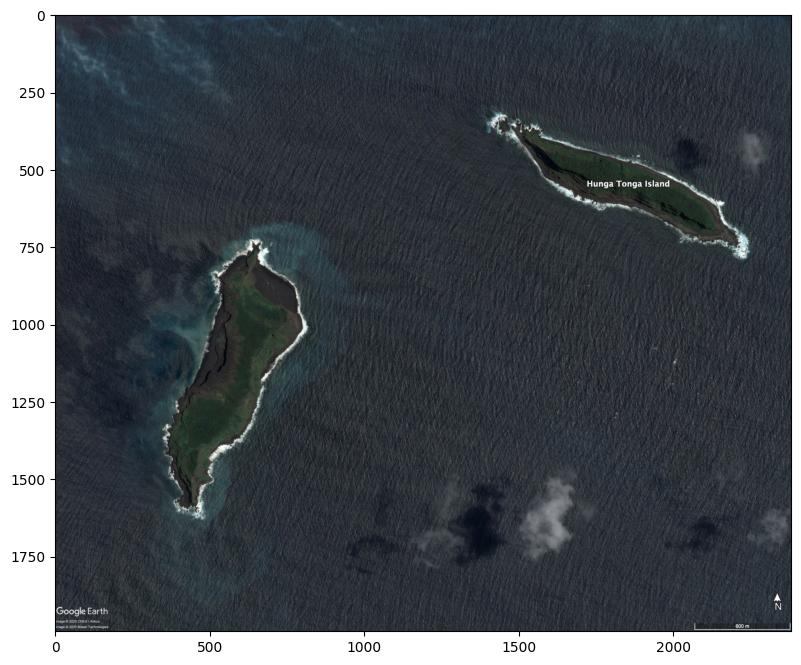

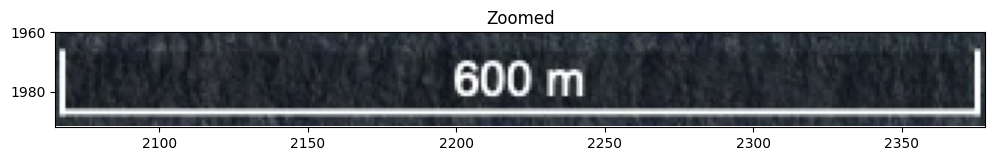

In [13]:
plt.figure(figsize=(12,8))
plt.imshow(image)
plt.show()

### zooming onto scale bar

plt.figure(figsize=(12,8))
plt.imshow(image)
plt.title("Zoomed")
plt.xlim(2065, 2378)   # adjusted to get the no. of pixels (313 -> 600 m)
plt.ylim(1992,1960)
plt.show()

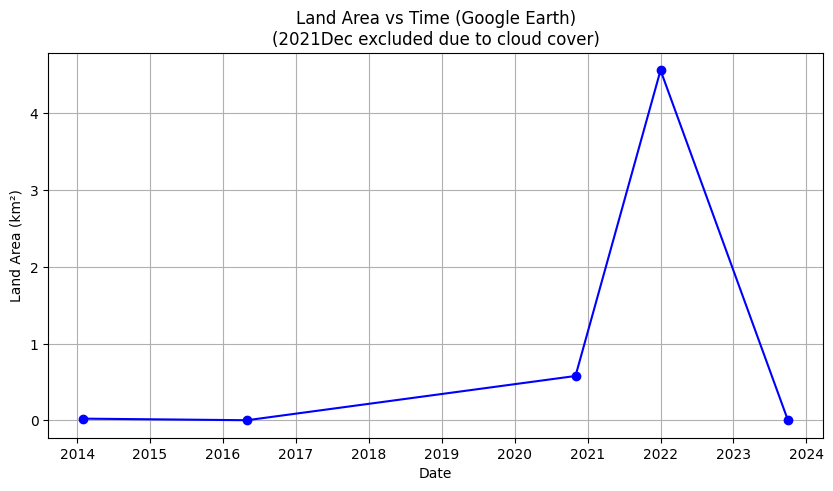

        Date  Land Area (km²)
0 2014-02-01         0.022415
1 2016-05-01         0.001837
2 2020-11-01         0.578387
3 2022-01-01         4.562790
4 2023-10-01         0.001837


In [14]:
images = [img for img in images if "2021Dec" not in img.name]

pixel_size = 600/313

dates, areas_km2 = [], []

for img_path in images:
    date = img_path.stem
    image = plt.imread(img_path)
    gray = np.mean(image, axis=2)# analogue for brightness of pixel

   # assuming land and water will have very different brightness
   # approximate measurement
    mask = gray < 0.5
    land_pixels = np.sum(mask)
    land_area_m2 = land_pixels*(pixel_size**2)

    dates.append(date)
    areas_km2.append(land_area_m2/1e4)

# converting dates so spacing in plot axis is correct
dates_dt = pd.to_datetime(dates, format="%Y%b")

plt.figure(figsize=(10,5))
plt.plot(dates_dt, areas_km2, marker='o', linestyle='-', color='blue')
plt.title("Land Area vs Time (Google Earth)\n(2021Dec excluded due to cloud cover)")
plt.xlabel("Date")
plt.ylabel("Land Area (km²)")
plt.grid(True)
plt.show()

df = pd.DataFrame({"Date": dates_dt, "Land Area (km²)": areas_km2})
print(df)


C:\Users\odunu\AppData\Local\Temp\ipykernel_47376\993260338.py:20: RuntimeWarning: invalid value encountered in divide
  ndvi = (nir - red)/(nir + red)


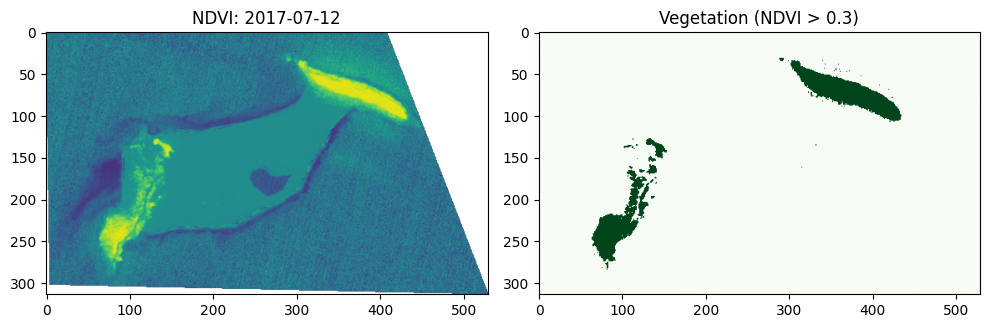

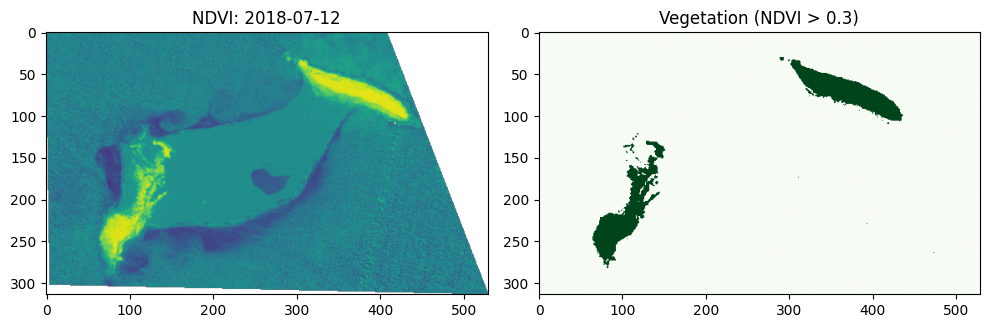

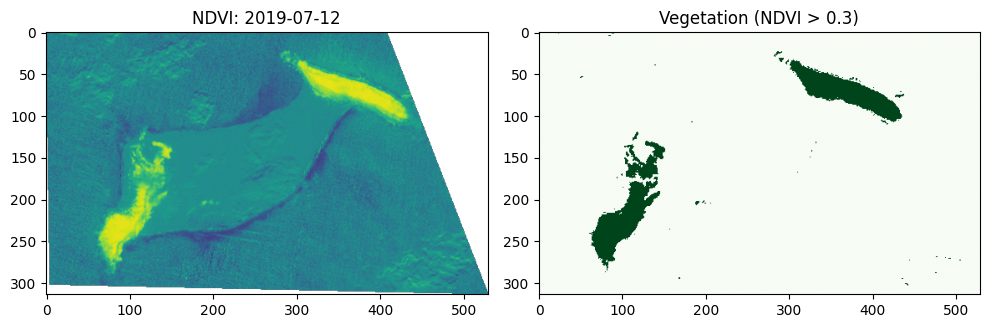

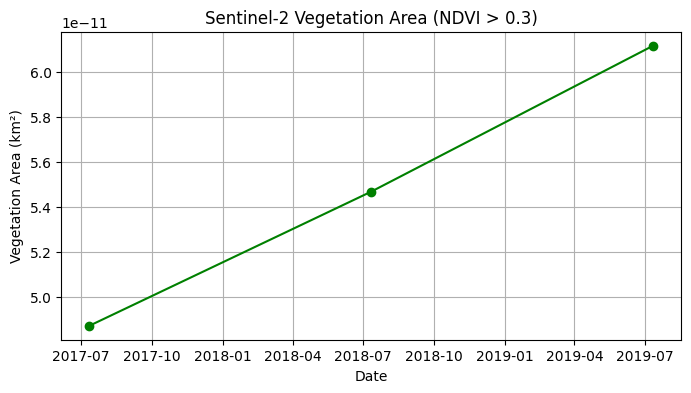

        Date  Vegetation Area (km²)
0 2017-07-12           4.873659e-11
1 2018-07-12           5.468783e-11
2 2019-07-12           6.116083e-11


In [15]:
data_dir = Path("sentinel-data")
threshold = 0.3

dates = []
areas_km2 = []

for folder in sorted(data_dir.glob("S2_*")):
    red_file = folder / "Sentinel-2_L2A_B04_Raw.tiff"
    nir_file = folder / "Sentinel-2_L2A_B08_Raw.tiff"

    # loading red (B4) and near infrared (B8) files needed for ndvi
    with rasterio.open(red_file) as red_src:
        red = red_src.read(1).astype(float)
        transform = red_src.transform

    with rasterio.open(nir_file) as nir_src:
        nir = nir_src.read(1).astype(float)

    # Normalised Difference Vegetation Index (NDVI)
    ndvi = (nir - red)/(nir + red)

    # masking vegetation
    veg_mask = ndvi > threshold
    veg_pixels = np.sum(veg_mask)

    # estimating pixel area from transform
    pixel_width = transform[0]
    pixel_height = -transform[4]
    pixel_area_m2 = pixel_width * pixel_height

    area_km2 = veg_pixels * pixel_area_m2 / 1e6

    # formatting date for analysis
    date = pd.to_datetime(folder.name.replace("S2_", ""))
    dates.append(date)
    areas_km2.append(area_km2)

    # visualisng vegetation
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(ndvi, cmap="viridis", vmin=-1, vmax=1)
    axes[0].set_title(f"NDVI: {date:%Y-%m-%d}")
    axes[1].imshow(veg_mask, cmap="Greens")
    axes[1].set_title(f"Vegetation (NDVI > {threshold})")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8,4))
plt.plot(dates, areas_km2, "o-", color="green")
plt.title(f"Sentinel-2 Vegetation Area (NDVI > {threshold})")
plt.xlabel("Date")
plt.ylabel("Vegetation Area (km²)")
plt.grid(True)
plt.show()

df = pd.DataFrame({"Date": dates, "Vegetation Area (km²)": areas_km2})
print(df)
